In [1]:
import torch
import matplotlib.pyplot as plt
from torch_geometric.datasets import Planetoid
from torch_geometric.utils import degree, to_networkx

c:\Users\Pablo\Desktop\Universidad\Master\Thesis\gnn_cora\.venv\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


In [9]:
# Download and load Cora
dataset = Planetoid(root="../data/", name="Cora")

# Cora contains a single graph
graph = dataset[0]
print(graph)

Data(x=[2708, 1433], edge_index=[2, 10556], y=[2708], train_mask=[2708], val_mask=[2708], test_mask=[2708])


In [10]:
print(f"Number of graphs: {len(dataset)}")
print(f"Number of nodes: {graph.num_nodes}")
print(f"Number of edges: {graph.num_edges}")
print(f"Features per node: {dataset.num_node_features}")
print(f"Number of classes: {dataset.num_classes}")

print(f"\nNode features shape: {graph.x.shape}")
print(f"Edge index shape: {graph.edge_index.shape}")
print(f"Labels shape: {graph.y.shape}")

print(f"\nTraining nodes: {graph.train_mask.sum().item()}")
print(f"Validation nodes: {graph.val_mask.sum().item()}")
print(f"Test nodes: {graph.test_mask.sum().item()}")

Number of graphs: 1
Number of nodes: 2708
Number of edges: 10556
Features per node: 1433
Number of classes: 7

Node features shape: torch.Size([2708, 1433])
Edge index shape: torch.Size([2, 10556])
Labels shape: torch.Size([2708])

Training nodes: 140
Validation nodes: 500
Test nodes: 1000


In [12]:
# Inspect the first node
node_id = 0

print("Node features (first 30):")
print(graph.x[node_id, :30])

print(f"\nNode class: {graph.y[node_id].item()}")

# Find all neighbours of node 0
# edge_index[0] contains source nodes
# edge_index[1] contains destination nodes
source_nodes = graph.edge_index[0]
target_nodes = graph.edge_index[1]

neighbours = target_nodes[source_nodes == node_id]

print(f"\nNeighbours of node {node_id}:")
print(neighbours.tolist())

Node features (first 30):
tensor([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.])

Node class: 3

Neighbours of node 0:
[633, 1862, 2582]


Average degree: 3.90
Maximum degree: 168
Isolated nodes: 0


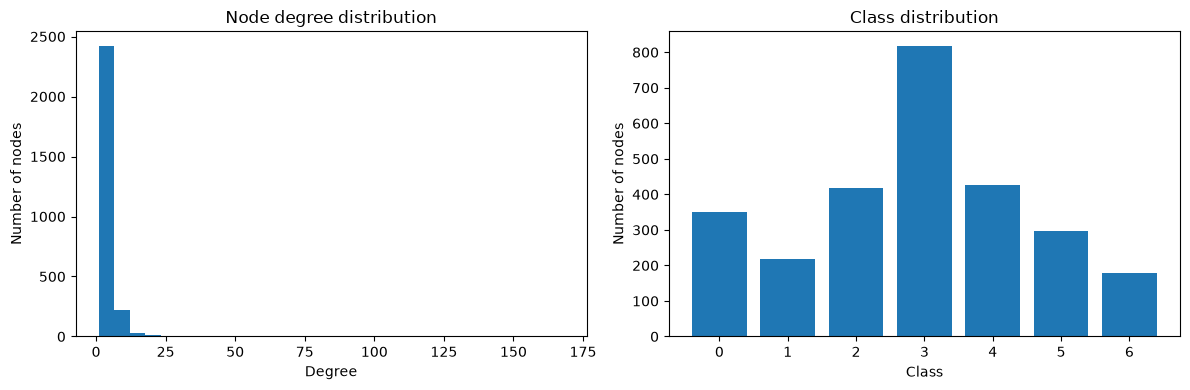

In [13]:
# Degree = number of connections associated with each node
node_degrees = degree(
    graph.edge_index[0],
    num_nodes=graph.num_nodes
)

print(f"Average degree: {node_degrees.mean():.2f}")
print(f"Maximum degree: {node_degrees.max().item():.0f}")
print(f"Isolated nodes: {(node_degrees == 0).sum().item()}")

# Count nodes in each class
class_counts = torch.bincount(
    graph.y,
    minlength=dataset.num_classes
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(node_degrees.numpy(), bins=30)
axes[0].set_title("Node degree distribution")
axes[0].set_xlabel("Degree")
axes[0].set_ylabel("Number of nodes")

axes[1].bar(
    range(dataset.num_classes),
    class_counts.numpy()
)
axes[1].set_title("Class distribution")
axes[1].set_xlabel("Class")
axes[1].set_ylabel("Number of nodes")

plt.tight_layout()
plt.show()